# Part 5 — Portfolio Analytics | Manager Research & Selection
**FE5108 · Portfolio Theory and Investments · Fall 2026**  
**Deliverable:** reproducible, fully annotated analysis of MSCI Value and the four-style blend (1995-01 through 2023-07).  
**How to use:** open in Jupyter or VS Code, select the project Python environment, then **Run All**. Every exhibit is produced from the supplied workbook. The PDF is generated separately using `python -m part5.reporting`.

**Investment committee question:** Is the extra sophistication in MSCI's factor indices delivering *incremental alpha*, or simply repackaging inexpensive market, size and value exposures?

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

# Works from either the repository root or the notebooks/ directory.
ROOT = Path.cwd().resolve()
if not (ROOT / 'pyproject.toml').exists():
    ROOT = ROOT.parent
assert (ROOT / 'pyproject.toml').exists(), 'Open this notebook from inside the goldman2 repository.'
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT))
from part5.analysis import load_sample, analyze, fit_factors, save_charts, OUT, FACTORS

OUT.mkdir(parents=True, exist_ok=True)
data = load_sample()
result, returns, active = analyze(data)
print(f"Sample: {result['n']} monthly observations, {result['start']} to {result['end']}")
print('Data: supplied Fama-French / MSCI workbook; monthly percentage-point returns.')

Sample: 343 monthly observations, 1995-01 to 2023-07
Data: supplied Fama-French / MSCI workbook; monthly percentage-point returns.


## 5A. What is MSCI actually selling? A value-definition audit

**The non-obvious distinction is that MSCI Value is not simply a portfolio of the cheapest stocks.** MSCI scores value using **book value/price, 12-month forward earnings/price and dividend yield**, while separately measuring growth through **long-term and short-term forward EPS growth, current internal growth, historical long-term EPS growth and historical long-term sales-per-share growth**. Because value and growth are evaluated separately, a stock can score well on both dimensions; the style indexes are not a binary cheap-versus-expensive split. Securities can receive partial style inclusion weights.

This is economically consequential. **Book/price** emphasizes accounting assets, **forward earnings/price** incorporates analysts' expectations of profitability, and **dividend yield** captures cash distributed to shareholders. A stock with weak book value but strong expected earnings need not be treated like a conventional high-book-to-market stock. The index is therefore a *multi-signal valuation screen*, not a pure bet on balance-sheet cheapness. MSCI also recognizes that a universal growth signal is not appropriate for every industry: the cited methodology excludes historical long-term sales-per-share growth for banks and diversified financials (subject to specified sub-industry exceptions), and excludes long-term forward EPS growth in Small Cap indexes. These are **sector/universe-specific measurement choices**, not evidence of superior performance.

**Exhibit 5A. What is being measured?**

| Due-diligence question | MSCI USA Value | Fama–French HML |
|---|---|---|
| What defines cheapness? | Book/price + forward earnings/price + dividend yield | High-minus-low book-to-market portfolio spread |
| Is growth assessed separately? | Yes; five forecast, internal and historical growth indicators | No comparable multi-indicator growth classification |
| Does classification vary by security type? | Yes; sector and index-size exceptions | Standard academic size/book-to-market sorts |
| What is the investable object? | Long-only, large/mid-cap style index | Long-short factor return spread, not a stand-alone long-only index |

**Investment implication.** MSCI's methodology may improve *classification* and investability, but that does not establish *alpha*. The test for a manager-selection team is whether the extra signals deliver returns that cannot be explained by inexpensive market, size and value exposures. Sections 5B–5D test precisely that. **Sources:** MSCI Global Investable Market Value and Growth Index Methodology (February 2021), §§1.2, 2.1–2.3; Fama–French factor definitions.


## 5B — Factor fingerprint: is MSCI Value as advertised?
**Question.** Regress gross monthly MSCI Value returns on RF, Mkt−RF, HML and SMB, including an intercept. Report coefficients and conventional OLS t-statistics.

The assignment calls this a pooled panel regression; because we have one index observed over time, this is correctly implemented as a time-series OLS. All return regressors and the dependent variable are measured in monthly percentage points.

In [2]:
model = fit_factors(data)
coef = pd.DataFrame({'Coefficient': model.params, 't-stat': model.tvalues,
                     'p-value': model.pvalues, 'CI lower': model.conf_int()[0],
                     'CI upper': model.conf_int()[1]})
display(coef.style.format('{:.4f}').set_caption('Exhibit 5B · MSCI Value factor fingerprint (OLS, n=343)'))
print(f'R-squared = {model.rsquared:.2%}; no Newey-West adjustment (as instructed).')

,Coefficient,t-stat,p-value,CI lower,CI upper
const,-0.0713,-0.9058,0.3657,-0.2261,0.0835
RF,0.8646,2.7885,0.0056,0.2547,1.4746
Mkt-RF,0.9480,76.9858,0.0000,0.9238,0.9723
HML,0.3216,19.6816,0.0000,0.2895,0.3538
SMB,-0.1744,-9.9046,0.0000,-0.2090,-0.1397


R-squared = 94.84%; no Newey-West adjustment (as instructed).


**Investment interpretation.** Positive HML identifies an authentic value tilt; negative SMB identifies a large-cap tilt that is *bundled* with value. A one-percentage-point HML shock maps to roughly +0.322 percentage points of index return, holding other regressors constant; a +1 pp SMB shock maps to about −0.174 pp. This is a descriptive factor fingerprint, not a causal trading forecast. The index is as advertised, but it is **not** a pure long-short HML position.

## 5C — Is there alpha after paying for standard factor exposures?
The intercept is the conditional monthly return not explained by the contemporaneous factor regressors. The central question is not whether MSCI has a sophisticated methodology, but whether that complexity produces a reliably positive intercept.

In [3]:
alpha = model.params['const']; t = model.tvalues['const']; p = model.pvalues['const']
print(f'Exhibit 5C · Monthly alpha: {alpha:.4f} pp; t={t:.2f}; p={p:.3f}')
print(f'Simple annualized alpha: {12*alpha:.3f} pp/year')
print('Decision: statistically significant positive alpha?' , 'YES' if alpha>0 and p<.05 else 'NO')

Exhibit 5C · Monthly alpha: -0.0713 pp; t=-0.91; p=0.366
Simple annualized alpha: -0.855 pp/year
Decision: statistically significant positive alpha? NO


**Investment interpretation.** Negative, statistically insignificant alpha means the sample does **not** support a claim that MSCI's elaborate value definition improved factor-adjusted returns. This is an in-sample attribution, not a randomized test of the methodology or an implementable arbitrage.

## 5D — Can a cheap factor basket replace MSCI Value?
We exclude the intercept and use the estimated RF, Mkt−RF, HML and SMB coefficients as factor-leg weights. This creates a gross *return replication*, not an automatically tradeable portfolio: financing, collateral and factor-leg instruments still have to be specified.

,Arithmetic annual return (%),CAGR (%),Annual volatility (%),Sharpe
Value,9.874,9.049,15.267,0.505
Replication,10.729,10.046,14.868,0.576


Monthly return correlation: 0.974
Replication formula:
(+0.8646) x RF + (+0.9480) x Mkt-RF + (+0.3216) x HML + (-0.1744) x SMB


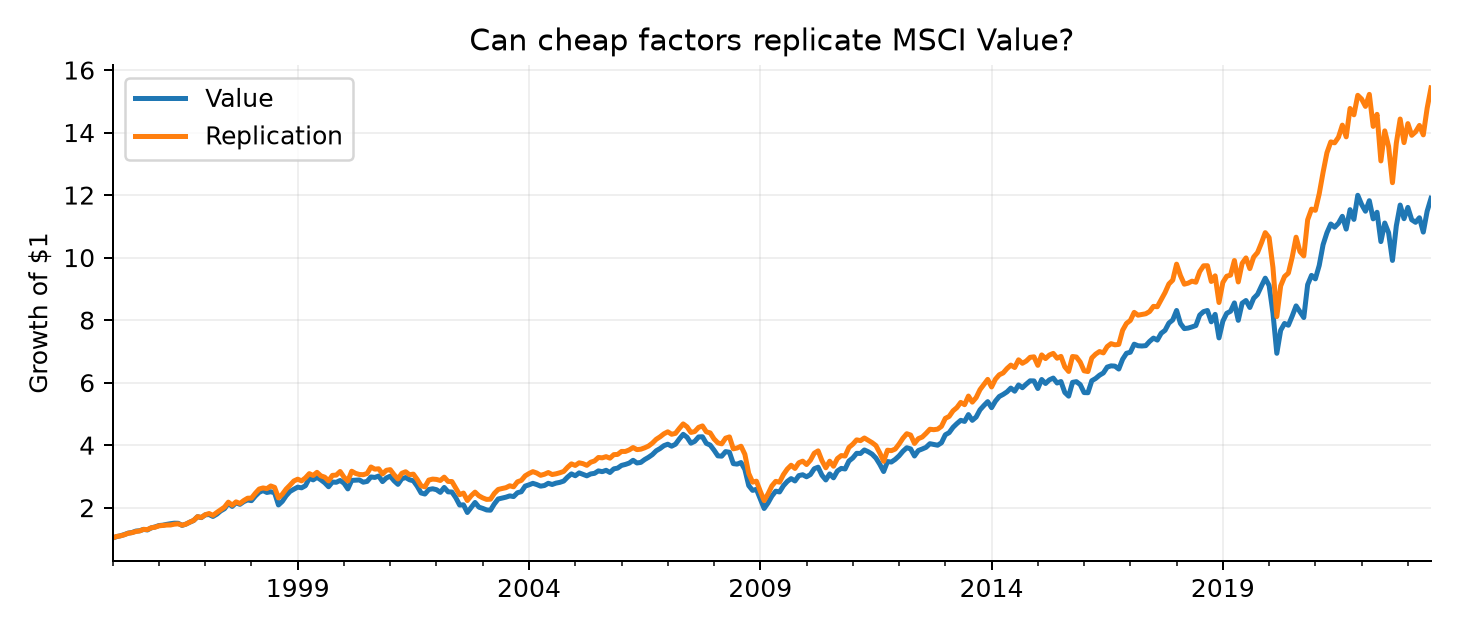

In [4]:
comparison = pd.DataFrame(result['portfolios']).T
comparison = comparison.rename(columns={'arithmetic_ann':'Arithmetic annual return (%)',
    'geometric_ann':'CAGR (%)','vol_ann':'Annual volatility (%)','sharpe':'Sharpe'})
display(comparison.style.format('{:.3f}').set_caption('Exhibit 5D · MSCI Value versus factor replication'))
print(f"Monthly return correlation: {result['replication_correlation']:.3f}")
print('Replication formula:')
print(' + '.join(f"({model.params[k]:+.4f}) x {k}" for k in ['RF','Mkt-RF','HML','SMB']))
save_charts(returns, active, result)
display(Image(filename=str(OUT / '5d_replication_growth.png')))

**Investment verdict.** A high return correlation supports in-sample tracking, but it does not establish a superior out-of-sample investment. The replication has a higher historical gross Sharpe; before choosing it, the investment committee should test **(i)** shorting/financing and transaction costs, **(ii)** liquidity and factor-leg investability, and **(iii)** coefficient stability with rolling, strictly out-of-sample estimation.

## 5E — Did diversification create *active* value?
Unlike absolute Sharpe, the information ratio asks whether the four-style portfolio earned enough *benchmark-relative* return to justify its active risk. Active monthly return = style return − MSCI USA market return. The blend is rebalanced monthly to 25% in each style.

,Annualized active return (%),Annualized tracking error (%),Information ratio
Value,-1.343,5.154,-0.261
MinVol,-0.796,6.380,-0.125
EqualWeight,0.588,5.396,0.109
Momentum,2.158,7.730,0.279
MultiFactor,0.152,3.387,0.045


IR = 12 × average monthly active return / (sqrt(12) × monthly active-return volatility)


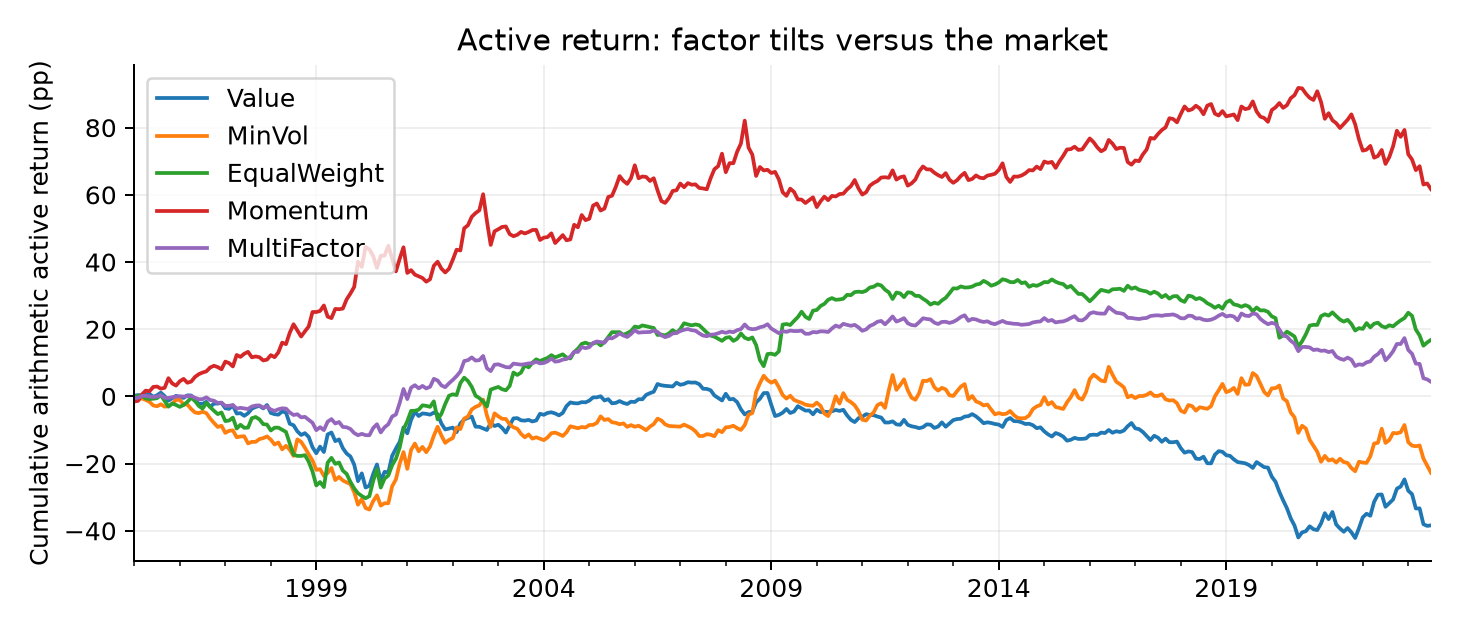

In [5]:
active_table = pd.DataFrame(result['active']).T.rename(columns={
'annual_excess':'Annualized active return (%)',
 'tracking_error':'Annualized tracking error (%)','information_ratio':'Information ratio'})
display(active_table.style.format('{:.3f}').set_caption('Exhibit 5E · Benchmark-relative performance'))
print('IR = 12 × average monthly active return / (sqrt(12) × monthly active-return volatility)')
display(Image(filename=str(OUT / '5e_active_returns.png')))

**Investment interpretation.** The blend has an information ratio near zero: diversification lowers tracking error relative to several single styles, but the realized active premium is too small to reward that risk meaningfully. A positive Sharpe ratio or attractive absolute growth curve is not sufficient evidence of benchmark-relative skill.

## 5F — Who consumes the tracking-error budget?
For equal weights, the variance identity is `Var(a_blend) = 1/4 × Σ Cov(a_blend, a_i)`. We report the **signed** contribution of each style as `Cov(a_blend, a_i) / [4 × Var(a_blend)]`, which sums to 100%. This incorporates cross-style correlation, not just each style's standalone volatility.

,Contribution to active variance (%)
MinVol,34.08
Momentum,24.81
Value,23.26
EqualWeight,17.86


Variance-share checksum = 100.0000000000%


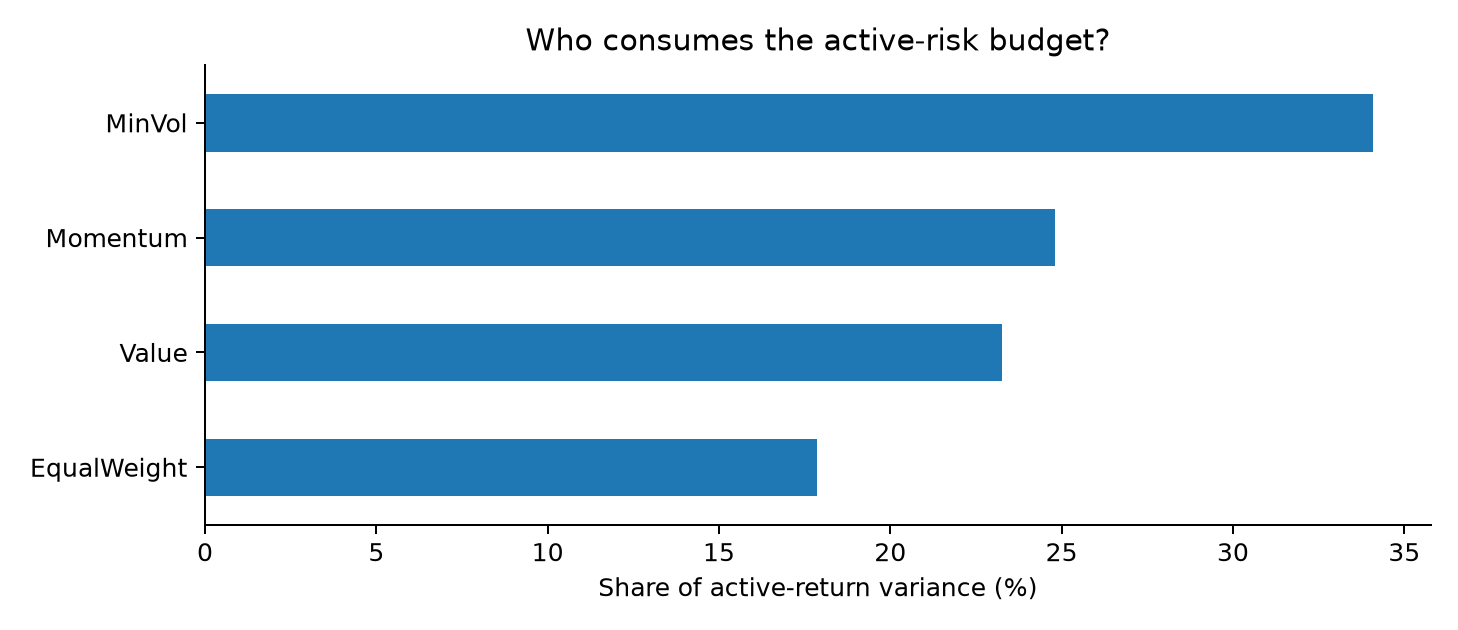

In [6]:
shares = pd.Series(result['variance_contributions']).mul(100).sort_values(ascending=False)
display(shares.to_frame('Contribution to active variance (%)').style.format('{:.2f}'))
print(f'Variance-share checksum = {shares.sum():.10f}%')
display(Image(filename=str(OUT / '5f_tracking_error_decomposition.png')))

**Manager-selection conclusion.** Minimum volatility consumes the largest share of the blend's active-risk budget. That does **not** contradict its defensive appeal: low-beta exposure may be valuable for a standalone investor while generating substantial tracking error against a cap-weighted equity benchmark. Under limits to arbitrage, the same strategy can be sensible in an absolute-risk mandate and problematic in a tightly benchmarked mandate.

### Methodology, reproducibility and caveats
- **Data:** `data/class-project-data-ff-msci-parts-1-and-5.xlsx`; Fama-French RF, Mkt−RF, SMB, HML and MSCI gross USD index levels. MSCI index returns are month-over-month percentage changes.
- **Window:** January 1995–July 2023 (343 months).
- **Statistics:** OLS with intercept; conventional t-statistics as specified in the assignment; annualized arithmetic return = 12 × monthly mean; annualized volatility and tracking error = sqrt(12) × monthly standard deviation; Sharpe uses FF RF.
- **Limitations:** Gross returns, in-sample factor coefficients, no realized implementation costs, no claim of out-of-sample alpha.
- **Source for 5A:** [MSCI Global Investable Market Value and Growth Index Methodology (Feb 2021)](https://www.msci.com/eqb/methodology/meth_docs/MSCI_GIMIVGMethod_Feb2021.pdf); academic HML from Fama-French definitions.

**Google Docs workflow:** copy the prose and tables from this notebook (or from the companion PDF); insert the three generated PNG exhibits from `part5/outputs/`.